In [ ]:
画二维Landscape对比图，使用测试集1 78 28三组参数
cmap='jet'
cmap='viridis'
cmap='viridis_r'
cmap='plasma'
cmap='turbo'
cmap='hot'

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# 1. 定义模型
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=4, hidden_dims=None):
        """
        支持动态隐藏层数的混合高斯模型。
        """
        super(MixtureOfGaussiansModel, self).__init__()
        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError("hidden_dims 不能为空，且需至少包含一层。")

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        # 动态构建隐藏层
        self.hidden_layers = nn.ModuleList()
        self.hidden_layers.append(nn.Linear(input_dim, hidden_dims[0]))
        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(nn.Linear(hidden_dims[i-1], hidden_dims[i]))

        # 输出层：每个组件 6 个参数 (w, mu_x, mu_y, s_xx, alpha, s_yy)
        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, x):
        """
        Returns:
            weights: [B, K]
            means: [B, K, 2]
            covariances: [B, K, 2, 2]
        """
        batch_size = x.shape[0]

        # 隐藏层 + ReLU
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        # 输出并重排
        output = self.output_layer(x).view(batch_size, self.num_components, 6)

        # 权重
        weights = F.softmax(output[:, :, 0], dim=1)  # [B,K]

        # 均值
        means = output[:, :, 1:3]  # [B,K,2]

        # 协方差参数化（数值稳定）
        eps = 1e-6
        s_xx  = F.softplus(output[:, :, 3]) + eps
        alpha = output[:, :, 4]
        rho   = 2 * torch.sigmoid(alpha) - 1
        rho   = torch.clamp(rho, -1 + 1e-4, 1 - 1e-4)
        s_yy  = F.softplus(output[:, :, 5]) + eps
        sigma_xy = rho * torch.sqrt(s_xx * s_yy)  # [B,K]

        covariances = torch.zeros(batch_size, self.num_components, 2, 2, device=x.device)
        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = sigma_xy
        covariances[:, :, 1, 0] = sigma_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances



预测的混合权重：
[0.18702295 0.49097997 0.18907452 0.13292255]

预测的均值：
[[ 2.1667256  -0.25359106]
 [ 1.4419996   1.4442888 ]
 [-0.2594939   2.1749659 ]
 [ 1.2914317   1.2838031 ]]

预测的协方差矩阵：
[[[ 0.08443265 -0.01646648]
  [-0.01646648  0.12191541]]

 [[ 0.08888972 -0.00576474]
  [-0.00576474  0.08869997]]

 [[ 0.12552613 -0.01680836]
  [-0.01680836  0.08462505]]

 [[ 0.26519018 -0.1759714 ]
  [-0.1759714   0.26413766]]]

Hellinger distance = 0.019606
PDF 文件已保存为: landscape_test_78.pdf


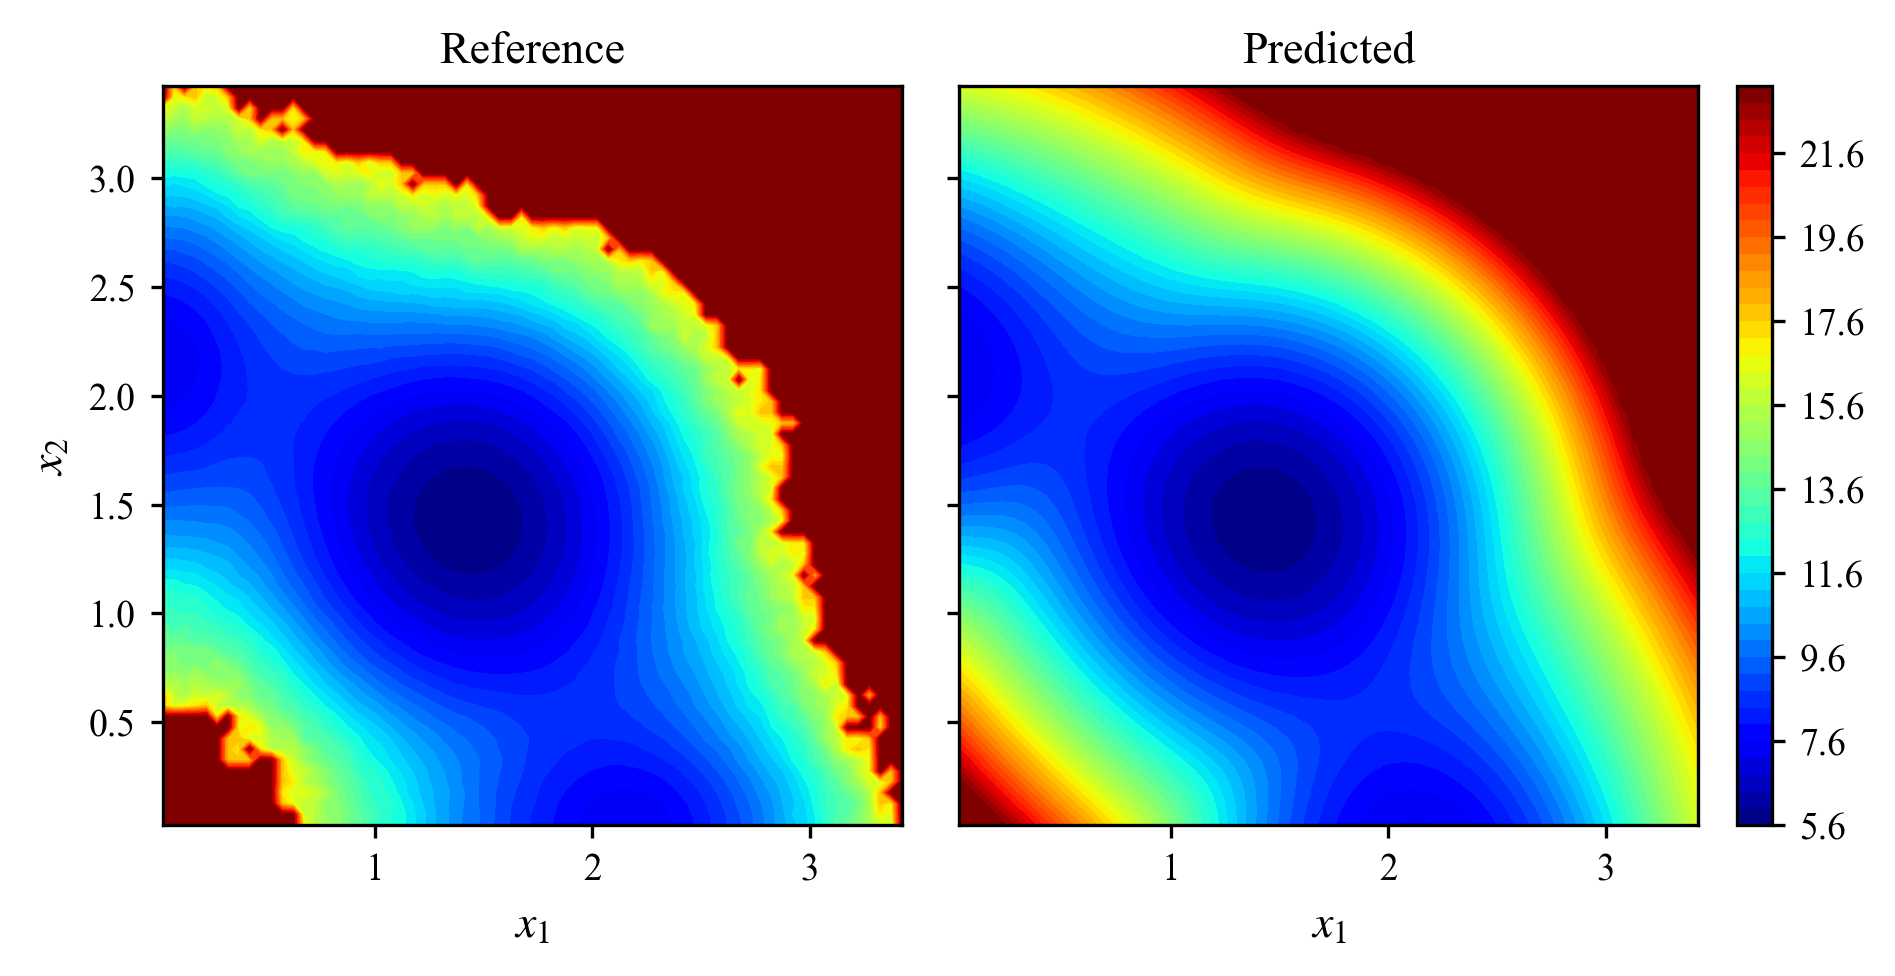

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.linewidth'] = 0.8

# 刻度线朝外
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=4,
    hidden_dims=[256, 512, 256]
)

model.load_state_dict(
    torch.load(
        'best_model_in4_K4_256-512-256_testloss0.051024.pth',
        map_location='cpu',
        weights_only=True
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [1.304882813,  1.154882813, 0.775976563, 0.364501953]   # test 1
input_params = [0.892382813,	0.442382813,	0.788476563,	0.442626953] # test 8
input_params = [1.361132813,	0.498632813,	0.944726563,	0.372314453] # test 46
input_params = [1.403320313,	0.737695313,	0.977539063,	0.417236328] # test 78
#input_params = [0.573632813,	0.386132813,	0.957226563,	0.169189453] # test 28
sample_id = 78

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 读取参考密度矩阵
# ============================================================
MAT_PATH = f'density_results_ps_test_n_cells=50000_edges=0.05/ps_test{{{sample_id}}}.mat'
MAT_KEY = 'density'

mat_data = loadmat(MAT_PATH)
ref_density = mat_data[MAT_KEY].astype(np.float64)

n_y, n_x = ref_density.shape


# ============================================================
# 4. 构造与参考密度一致的网格
# ============================================================
grid_step = 0.05

x_grid = np.arange(n_x) * grid_step + grid_step / 2
y_grid = np.arange(n_y) * grid_step + grid_step / 2

X, Y = np.meshgrid(x_grid, y_grid)
pos = np.dstack((X, Y))


# ============================================================
# 5. 得到模型预测参数
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights = weights[0].cpu().numpy()
means = means[0].cpu().numpy()
covariances = covariances[0].cpu().numpy()

print("预测的混合权重：")
print(weights)

print("\n预测的均值：")
print(means)

print("\n预测的协方差矩阵：")
print(covariances)


# ============================================================
# 6. 在同一个网格上计算预测密度
# ============================================================
pred_density = np.zeros_like(X, dtype=np.float64)

for i in range(len(weights)):
    cov_i = covariances[i]

    # 防止协方差矩阵数值上不正定
    cov_i = cov_i + np.eye(2) * 1e-8

    rv = multivariate_normal(
        mean=means[i],
        cov=cov_i,
        allow_singular=True
    )

    pred_density += weights[i] * rv.pdf(pos)

pred_density = pred_density / (pred_density.sum() + 1e-12)


# ============================================================
# 7. 计算 Hellinger 距离
# ============================================================
ref_density_for_metric = ref_density / (ref_density.sum() + 1e-12)

hellinger = np.sqrt(
    0.5 * np.sum(
        (np.sqrt(ref_density_for_metric) - np.sqrt(pred_density)) ** 2
    )
)

print(f"\nHellinger distance = {hellinger:.6f}")


# ============================================================
# 8. 转成 landscape: U = -log(P)
# ============================================================
eps = 1e-10

ref_landscape = -np.log(np.maximum(ref_density, eps))
pred_landscape = -np.log(np.maximum(pred_density, eps))

vmin = min(ref_landscape.min(), pred_landscape.min())
vmax = max(ref_landscape.max(), pred_landscape.max())


# ============================================================
# 9. 论文风格绘图
# ============================================================
fig = plt.figure(figsize=(7.0, 3.2))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.045],
    wspace=0.04
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])


# ----------------------------
# 左图：Reference Landscape
# ----------------------------
cf1 = ax1.contourf(
    X,
    Y,
    ref_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax1.set_title('Reference', pad=6)
ax1.set_xlabel(r'$x_1$')
ax1.set_ylabel(r'$x_2$')
ax1.set_aspect('equal')


# ----------------------------
# 右图：Predicted Landscape
# ----------------------------
cf2 = ax2.contourf(
    X,
    Y,
    pred_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax2.set_title(f'Predicted', pad=6)
ax2.set_xlabel(r'$x_1$')
ax2.set_ylabel('')
ax2.set_aspect('equal')


# ----------------------------
# 坐标轴细节美化：
# 只保留下侧和左侧刻度线
# ----------------------------
for ax in [ax1, ax2]:
    ax.tick_params(
        axis='both',
        which='both',
        direction='out',
        bottom=True,
        left=True,
        top=False,
        right=False,
        length=3,
        width=0.8
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

# 第二张图保留左侧 y 轴刻度线，但不显示 y 轴数字和 y 轴标签
ax2.tick_params(
    axis='y',
    left=True,
    labelleft=False,
    right=False,
    labelright=False,
    direction='out'
)

ax2.set_ylabel('')


# ----------------------------
# 共享 colorbar
# ----------------------------
cbar = fig.colorbar(cf2, cax=cax)

#cbar.set_label(r'Landscape', labelpad=6)

cbar.ax.tick_params(
    direction='out',
    length=3,
    width=0.8,
    labelsize=9
)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# 10. 保存为 PDF 文件并显示
# ============================================================
SAVE_FIG = True

if SAVE_FIG:
    pdf_name = f'landscape_test_{sample_id}.pdf'

    plt.savefig(
        pdf_name,
        format='pdf',
        dpi=800,
        bbox_inches='tight',
        pad_inches=0.02,
        facecolor='white',
        transparent=False
    )

    print(f"PDF 文件已保存为: {pdf_name}")

plt.show()

预测的混合权重：
[0.15372573 0.5866321  0.15333189 0.10631026]

预测的均值：
[[ 3.1797922  -0.20678073]
 [ 1.681471    1.6807581 ]
 [-0.20284405  3.1801786 ]
 [ 1.6918522   1.695625  ]]

预测的协方差矩阵：
[[[ 0.07390799 -0.02053036]
  [-0.02053036  0.10566483]]

 [[ 0.08420716 -0.00290948]
  [-0.00290948  0.0843585 ]]

 [[ 0.10314474 -0.02014403]
  [-0.02014403  0.07414495]]

 [[ 0.67124563 -0.58080614]
  [-0.58080614  0.6705319 ]]]

Hellinger distance = 0.019256
PDF 文件已保存为: landscape_test_1.pdf


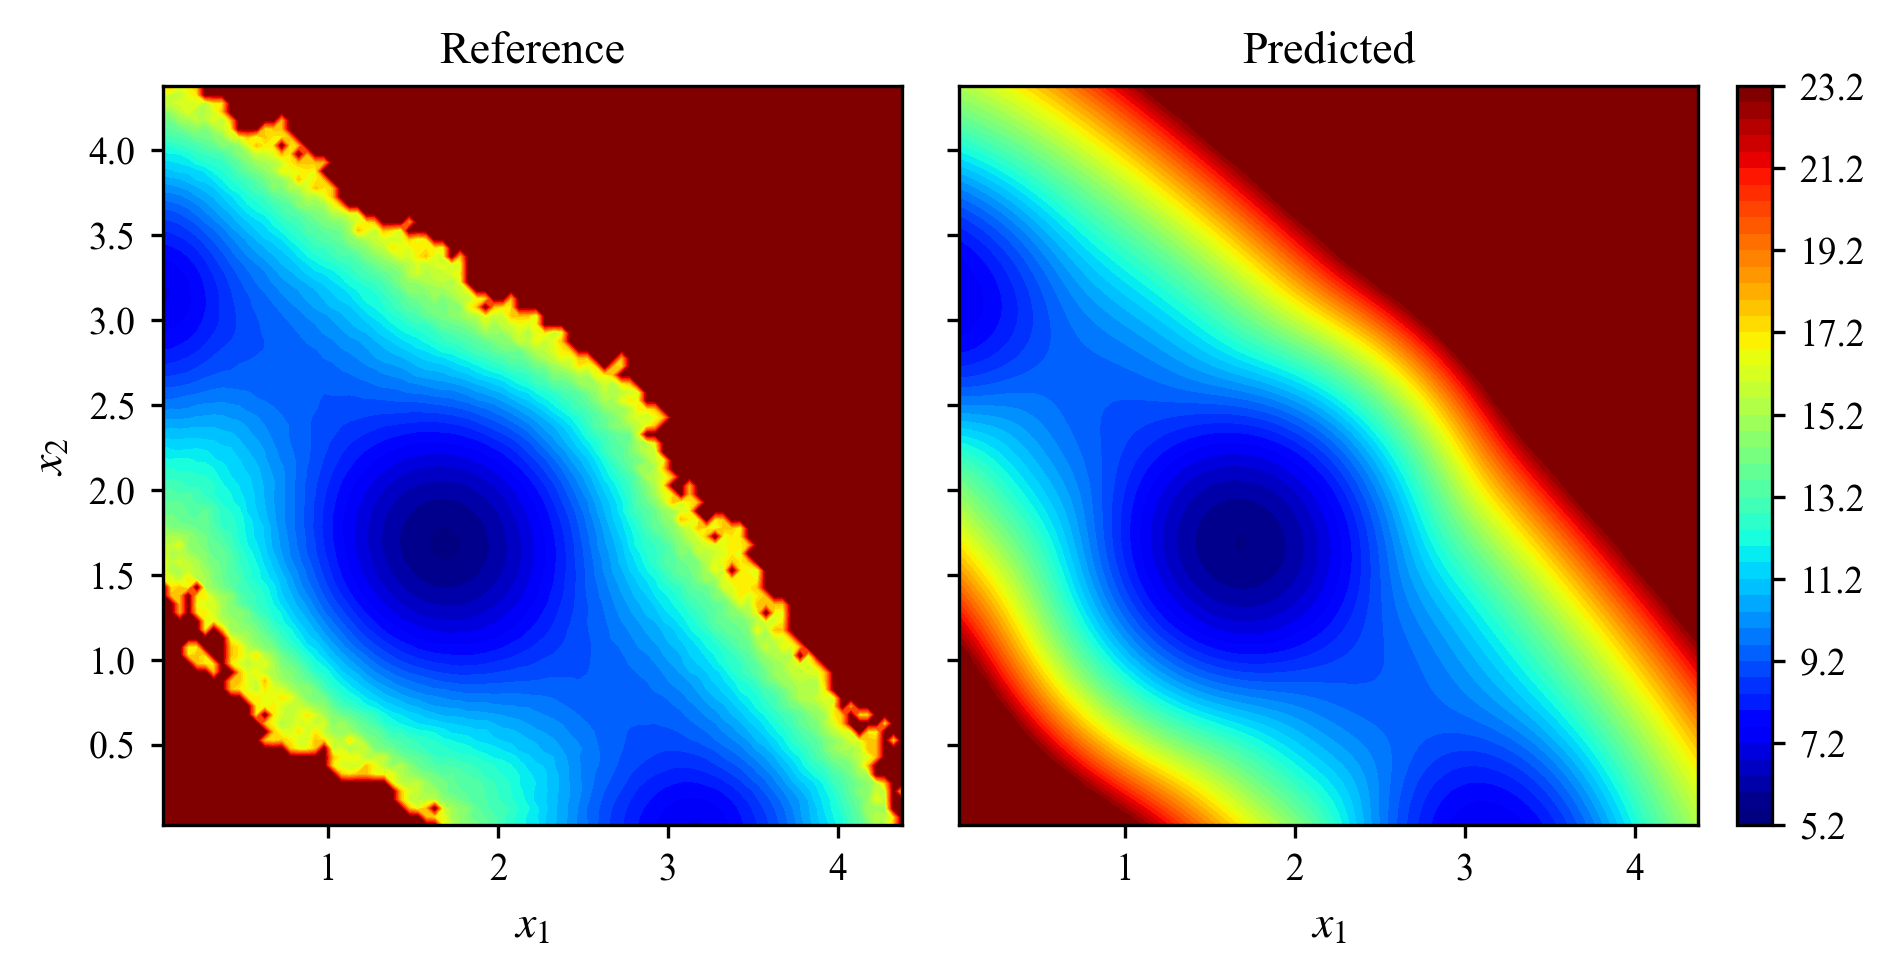

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.linewidth'] = 0.8

# 刻度线朝外
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=4,
    hidden_dims=[256, 512, 256]
)

model.load_state_dict(
    torch.load(
        'best_model_in4_K4_256-512-256_testloss0.051024.pth',
        map_location='cpu',
        weights_only=True
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [1.304882813,  1.154882813, 0.775976563, 0.364501953]   # test 1
#input_params = [0.892382813,	0.442382813,	0.788476563,	0.442626953] # test 8
#input_params = [1.361132813,	0.498632813,	0.944726563,	0.372314453] # test 46
#input_params = [1.403320313,	0.737695313,	0.977539063,	0.417236328] # test 78
#input_params = [0.573632813,	0.386132813,	0.957226563,	0.169189453] # test 28
sample_id = 1

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 读取参考密度矩阵
# ============================================================
MAT_PATH = f'density_results_ps_test_n_cells=50000_edges=0.05/ps_test{{{sample_id}}}.mat'
MAT_KEY = 'density'

mat_data = loadmat(MAT_PATH)
ref_density = mat_data[MAT_KEY].astype(np.float64)

n_y, n_x = ref_density.shape


# ============================================================
# 4. 构造与参考密度一致的网格
# ============================================================
grid_step = 0.05

x_grid = np.arange(n_x) * grid_step + grid_step / 2
y_grid = np.arange(n_y) * grid_step + grid_step / 2

X, Y = np.meshgrid(x_grid, y_grid)
pos = np.dstack((X, Y))


# ============================================================
# 5. 得到模型预测参数
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights = weights[0].cpu().numpy()
means = means[0].cpu().numpy()
covariances = covariances[0].cpu().numpy()

print("预测的混合权重：")
print(weights)

print("\n预测的均值：")
print(means)

print("\n预测的协方差矩阵：")
print(covariances)


# ============================================================
# 6. 在同一个网格上计算预测密度
# ============================================================
pred_density = np.zeros_like(X, dtype=np.float64)

for i in range(len(weights)):
    cov_i = covariances[i]

    # 防止协方差矩阵数值上不正定
    cov_i = cov_i + np.eye(2) * 1e-8

    rv = multivariate_normal(
        mean=means[i],
        cov=cov_i,
        allow_singular=True
    )

    pred_density += weights[i] * rv.pdf(pos)

pred_density = pred_density / (pred_density.sum() + 1e-12)


# ============================================================
# 7. 计算 Hellinger 距离
# ============================================================
ref_density_for_metric = ref_density / (ref_density.sum() + 1e-12)

hellinger = np.sqrt(
    0.5 * np.sum(
        (np.sqrt(ref_density_for_metric) - np.sqrt(pred_density)) ** 2
    )
)

print(f"\nHellinger distance = {hellinger:.6f}")


# ============================================================
# 8. 转成 landscape: U = -log(P)
# ============================================================
eps = 1e-10

ref_landscape = -np.log(np.maximum(ref_density, eps))
pred_landscape = -np.log(np.maximum(pred_density, eps))

vmin = min(ref_landscape.min(), pred_landscape.min())
vmax = max(ref_landscape.max(), pred_landscape.max())


# ============================================================
# 9. 论文风格绘图
# ============================================================
fig = plt.figure(figsize=(7.0, 3.2))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.045],
    wspace=0.04
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])


# ----------------------------
# 左图：Reference Landscape
# ----------------------------
cf1 = ax1.contourf(
    X,
    Y,
    ref_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax1.set_title('Reference', pad=6)
ax1.set_xlabel(r'$x_1$')
ax1.set_ylabel(r'$x_2$')
ax1.set_aspect('equal')


# ----------------------------
# 右图：Predicted Landscape
# ----------------------------
cf2 = ax2.contourf(
    X,
    Y,
    pred_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax2.set_title(f'Predicted', pad=6)
ax2.set_xlabel(r'$x_1$')
ax2.set_ylabel('')
ax2.set_aspect('equal')


# ----------------------------
# 坐标轴细节美化：
# 只保留下侧和左侧刻度线
# ----------------------------
for ax in [ax1, ax2]:
    ax.tick_params(
        axis='both',
        which='both',
        direction='out',
        bottom=True,
        left=True,
        top=False,
        right=False,
        length=3,
        width=0.8
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

# 第二张图保留左侧 y 轴刻度线，但不显示 y 轴数字和 y 轴标签
ax2.tick_params(
    axis='y',
    left=True,
    labelleft=False,
    right=False,
    labelright=False,
    direction='out'
)

ax2.set_ylabel('')


# ----------------------------
# 共享 colorbar
# ----------------------------
cbar = fig.colorbar(cf2, cax=cax)

#cbar.set_label(r'Landscape', labelpad=6)

cbar.ax.tick_params(
    direction='out',
    length=3,
    width=0.8,
    labelsize=9
)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# 10. 保存为 PDF 文件并显示
# ============================================================
SAVE_FIG = True

if SAVE_FIG:
    pdf_name = f'landscape_test_{sample_id}.pdf'

    plt.savefig(
        pdf_name,
        format='pdf',
        dpi=800,
        bbox_inches='tight',
        pad_inches=0.02,
        facecolor='white',
        transparent=False
    )

    print(f"PDF 文件已保存为: {pdf_name}")

plt.show()

预测的混合权重：
[4.9777058e-01 3.3580980e-04 4.9240577e-01 9.4878441e-03]

预测的均值：
[[ 0.9673363  -0.01326786]
 [ 0.67906976  0.6779566 ]
 [-0.00846319  0.9661436 ]
 [ 0.5530642   0.5739336 ]]

预测的协方差矩阵：
[[[ 0.02012096 -0.00509695]
  [-0.00509695  0.02725889]]

 [[ 0.08879458 -0.07305373]
  [-0.07305373  0.08901834]]

 [[ 0.02651978 -0.00507794]
  [-0.00507794  0.02043604]]

 [[ 0.30680394 -0.28885847]
  [-0.28885847  0.30418235]]]

Hellinger distance = 0.055947
PDF 文件已保存为: landscape_test_28.pdf


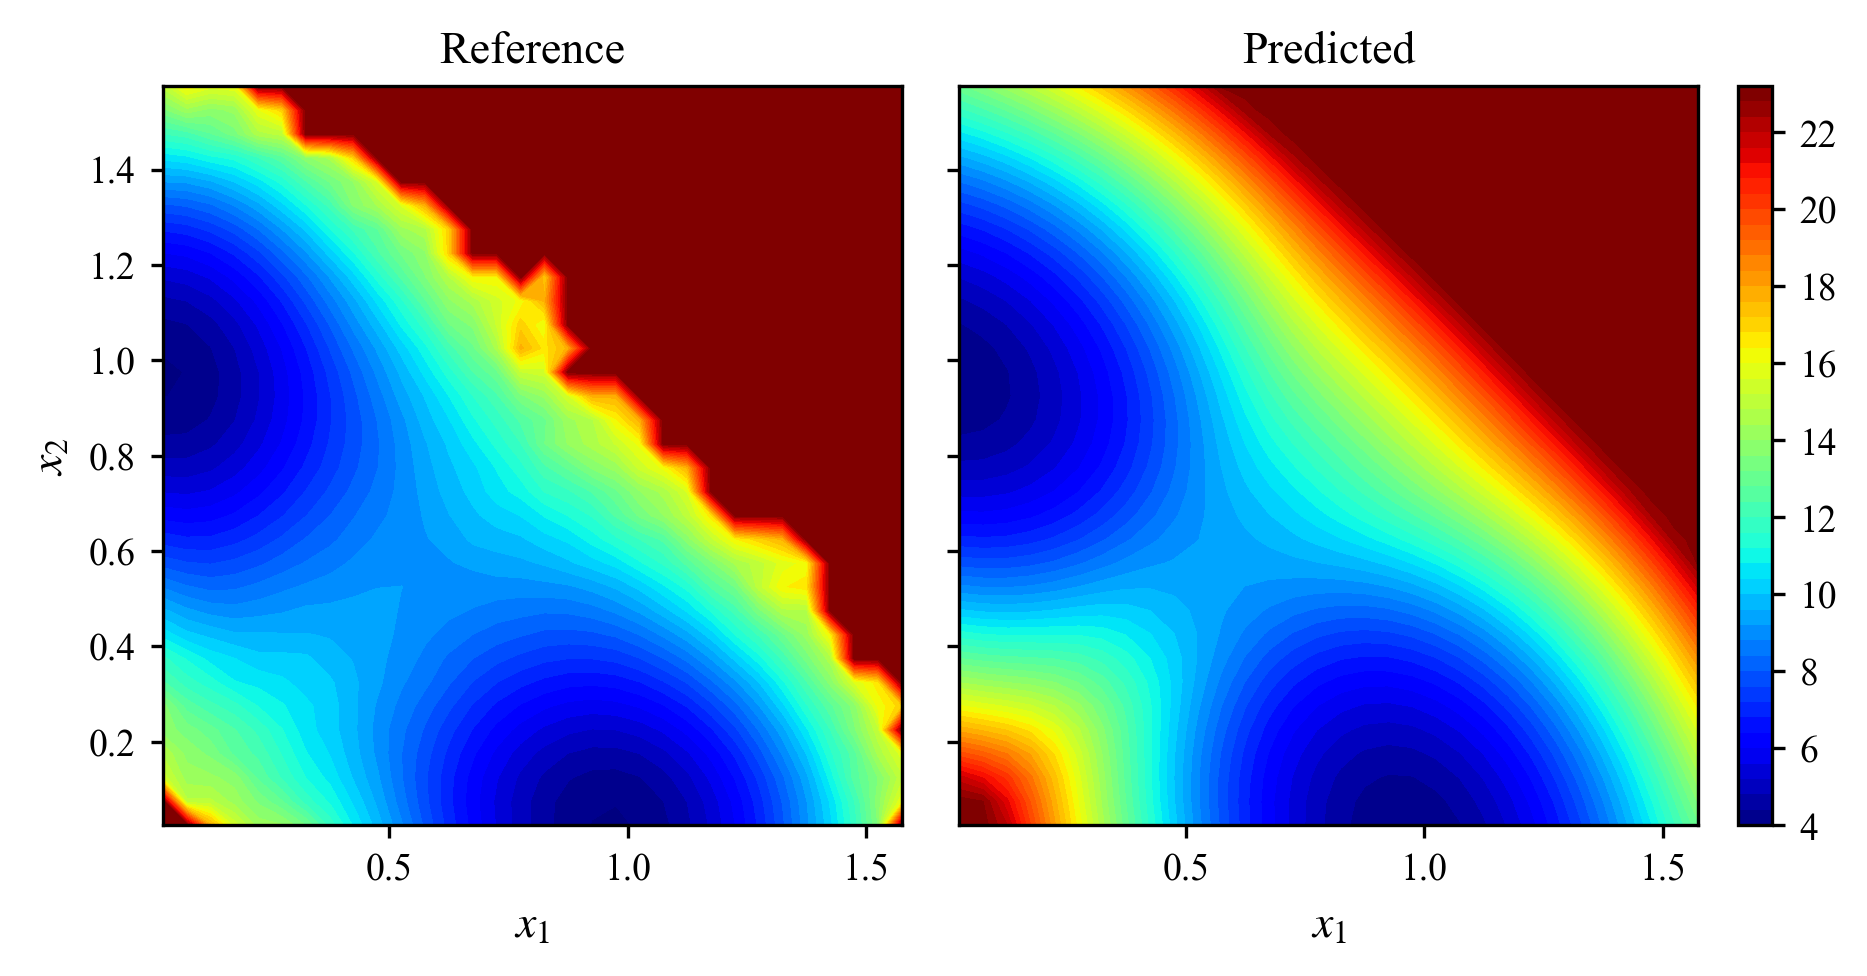

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.linewidth'] = 0.8

# 刻度线朝外
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=4,
    hidden_dims=[256, 512, 256]
)

model.load_state_dict(
    torch.load(
        'best_model_in4_K4_256-512-256_testloss0.051024.pth',
        map_location='cpu',
        weights_only=True
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
#input_params = [1.304882813,  1.154882813, 0.775976563, 0.364501953]   # test 1
#input_params = [0.892382813,	0.442382813,	0.788476563,	0.442626953] # test 8
#input_params = [1.361132813,	0.498632813,	0.944726563,	0.372314453] # test 46
#input_params = [1.403320313,	0.737695313,	0.977539063,	0.417236328] # test 78
input_params = [0.573632813,	0.386132813,	0.957226563,	0.169189453] # test 28
sample_id = 28

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 读取参考密度矩阵
# ============================================================
MAT_PATH = f'density_results_ps_test_n_cells=50000_edges=0.05/ps_test{{{sample_id}}}.mat'
MAT_KEY = 'density'

mat_data = loadmat(MAT_PATH)
ref_density = mat_data[MAT_KEY].astype(np.float64)

n_y, n_x = ref_density.shape


# ============================================================
# 4. 构造与参考密度一致的网格
# ============================================================
grid_step = 0.05

x_grid = np.arange(n_x) * grid_step + grid_step / 2
y_grid = np.arange(n_y) * grid_step + grid_step / 2

X, Y = np.meshgrid(x_grid, y_grid)
pos = np.dstack((X, Y))


# ============================================================
# 5. 得到模型预测参数
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

weights = weights[0].cpu().numpy()
means = means[0].cpu().numpy()
covariances = covariances[0].cpu().numpy()

print("预测的混合权重：")
print(weights)

print("\n预测的均值：")
print(means)

print("\n预测的协方差矩阵：")
print(covariances)


# ============================================================
# 6. 在同一个网格上计算预测密度
# ============================================================
pred_density = np.zeros_like(X, dtype=np.float64)

for i in range(len(weights)):
    cov_i = covariances[i]

    # 防止协方差矩阵数值上不正定
    cov_i = cov_i + np.eye(2) * 1e-8

    rv = multivariate_normal(
        mean=means[i],
        cov=cov_i,
        allow_singular=True
    )

    pred_density += weights[i] * rv.pdf(pos)

pred_density = pred_density / (pred_density.sum() + 1e-12)


# ============================================================
# 7. 计算 Hellinger 距离
# ============================================================
ref_density_for_metric = ref_density / (ref_density.sum() + 1e-12)

hellinger = np.sqrt(
    0.5 * np.sum(
        (np.sqrt(ref_density_for_metric) - np.sqrt(pred_density)) ** 2
    )
)

print(f"\nHellinger distance = {hellinger:.6f}")


# ============================================================
# 8. 转成 landscape: U = -log(P)
# ============================================================
eps = 1e-10

ref_landscape = -np.log(np.maximum(ref_density, eps))
pred_landscape = -np.log(np.maximum(pred_density, eps))

vmin = min(ref_landscape.min(), pred_landscape.min())
vmax = max(ref_landscape.max(), pred_landscape.max())


# ============================================================
# 9. 论文风格绘图
# ============================================================
fig = plt.figure(figsize=(7.0, 3.2))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.045],
    wspace=0.04
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])


# ----------------------------
# 左图：Reference Landscape
# ----------------------------
cf1 = ax1.contourf(
    X,
    Y,
    ref_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax1.set_title('Reference', pad=6)
ax1.set_xlabel(r'$x_1$')
ax1.set_ylabel(r'$x_2$')
ax1.set_aspect('equal')


# ----------------------------
# 右图：Predicted Landscape
# ----------------------------
cf2 = ax2.contourf(
    X,
    Y,
    pred_landscape,
    levels=50,
    cmap='jet',
    vmin=vmin,
    vmax=vmax
)

ax2.set_title(f'Predicted', pad=6)
ax2.set_xlabel(r'$x_1$')
ax2.set_ylabel('')
ax2.set_aspect('equal')


# ----------------------------
# 坐标轴细节美化：
# 只保留下侧和左侧刻度线
# ----------------------------
for ax in [ax1, ax2]:
    ax.tick_params(
        axis='both',
        which='both',
        direction='out',
        bottom=True,
        left=True,
        top=False,
        right=False,
        length=3,
        width=0.8
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

# 第二张图保留左侧 y 轴刻度线，但不显示 y 轴数字和 y 轴标签
ax2.tick_params(
    axis='y',
    left=True,
    labelleft=False,
    right=False,
    labelright=False,
    direction='out'
)

ax2.set_ylabel('')


# ----------------------------
# 共享 colorbar
# ----------------------------
cbar = fig.colorbar(cf2, cax=cax)

#cbar.set_label(r'Landscape', labelpad=6)

cbar.ax.tick_params(
    direction='out',
    length=3,
    width=0.8,
    labelsize=9
)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# 10. 保存为 PDF 文件并显示
# ============================================================
SAVE_FIG = True

if SAVE_FIG:
    pdf_name = f'landscape_test_{sample_id}.pdf'

    plt.savefig(
        pdf_name,
        format='pdf',
        dpi=800,
        bbox_inches='tight',
        pad_inches=0.02,
        facecolor='white',
        transparent=False
    )

    print(f"PDF 文件已保存为: {pdf_name}")

plt.show()